# Ideas de ML para FWI: prueba controlada en un problema de juguete

Este notebook evalúa las tres ideas más prometedoras de la lluvia de ideas. Todas comparten el mismo
problema (`fwi_toy.py`, acústica 2D en diferencias finitas, en lugar de SPECFEM3D). La comparación se hace con el mismo
**presupuesto de 100 simulaciones caras**, y en ese conteo entran todas: forward, adjuntas, Born, verificaciones
rechazadas y simulaciones en malla gruesa (pesadas por su costo).

| # | Idea | Hipótesis | Implementación |
|---|---|---|---|
| 1 | **Precondicionador SPD aprendido online** | Aprender un H0 espacial (iluminación × desenfoque) a partir de los pares (s, y) acelera L-BFGS | `ml_ideas.LearnedPrecond` |
| 2 | **Surrogate multifidelidad + región de confianza** | Una malla gruesa (1/8 del costo) con una corrección aprendida en el espacio de datos predice δd bien y permite pasos largos | `ml_ideas.run_mf_trust_region` |
| 3 | **Consulta Born adaptativa** | Pedir el producto Bv exacto solo cuando el surrogate lo necesite (por incertidumbre o por ρ) ahorra simulaciones | `fwi_toy.run_trust_region(born_mode=...)` |

Escenarios:
1. Gradiente con dos anomalías gaussianas y una capa delgada.
2. Capas buzantes cortadas por una falla, con una lente rápida.

Los resultados se cachean en `results/s<escenario>/<experimento>.pt`. Para regenerarlos:
`PYTHONPATH=. FWI_SCENARIO=1 python run_ml_experiments.py L-BFGS L-BFGS+P ...`
(corre una sola tarea de GPU a la vez).

In [1]:
import os, subprocess, sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

RUN_MISSING = False          # True: ejecuta los experimentos que falten (≈2 min cada uno en GPU)
SCEN = [1, 2]
EXP = {
    1: ["L-BFGS", "L-BFGS-mem50", "L-BFGS+G2", "L-BFGS+G4", "L-BFGS+P", "L-BFGS+P-illum", "L-BFGS+P-kernel",
        "L-BFGS+P-eps0.3", "L-BFGS+P-k5", "L-BFGS+P-reg0.1",
        "TR-secante", "TR-Born", "TR-Born-adapt", "TR-Born-rho", "MF-TR", "MF-TR+corr"],
    2: ["L-BFGS", "L-BFGS-mem50", "L-BFGS+G2", "L-BFGS+G4", "L-BFGS+P", "L-BFGS+P-illum", "L-BFGS+P-kernel",
        "L-BFGS+P-transfer", "L-BFGS+P-transfer-ft",
        "TR-secante", "TR-Born", "TR-Born-rho", "MF-TR+corr"],
}
env = dict(os.environ, PYTHONPATH=".")
for s in SCEN:
    missing = [n for n in EXP[s] if not os.path.exists(f"results/s{s}/{n}.pt")]
    if missing and RUN_MISSING:
        subprocess.run([sys.executable, "run_ml_experiments.py", *missing], env=dict(env, FWI_SCENARIO=str(s)), check=True)
    if not os.path.exists(f"results/s{s}/models.npz"):
        code = ("import numpy as np, fwi_toy as T; np.savez(f'results/s{T.SCENARIO}/models.npz', "
                "v_true=T.v_true_np, v_init=T.v_init_np, mask=T.mask_np)")
        subprocess.run([sys.executable, "-c", code], env=dict(env, FWI_SCENARIO=str(s)), check=True)

R = {s: {n: torch.load(f"results/s{s}/{n}.pt", weights_only=False) for n in EXP[s]
         if os.path.exists(f"results/s{s}/{n}.pt")} for s in SCEN}
MOD = {s: np.load(f"results/s{s}/models.npz") for s in SCEN}
J0 = {s: R[s]["L-BFGS"]["trace"][0][1] for s in SCEN}
E0 = {s: R[s]["L-BFGS"]["log"][0]["err"] for s in SCEN}
print({s: sorted(R[s]) for s in SCEN})

{1: ['L-BFGS', 'L-BFGS+G2', 'L-BFGS+G4', 'L-BFGS+P', 'L-BFGS+P-eps0.3', 'L-BFGS+P-illum', 'L-BFGS+P-k5', 'L-BFGS+P-kernel', 'L-BFGS+P-reg0.1', 'L-BFGS-mem50', 'MF-TR', 'MF-TR+corr', 'TR-Born', 'TR-Born-adapt', 'TR-Born-rho', 'TR-secante'], 2: ['L-BFGS', 'L-BFGS+G2', 'L-BFGS+G4', 'L-BFGS+P', 'L-BFGS+P-illum', 'L-BFGS+P-kernel', 'L-BFGS+P-transfer', 'L-BFGS+P-transfer-ft', 'L-BFGS-mem50', 'MF-TR+corr', 'TR-Born', 'TR-Born-rho', 'TR-secante']}


## Resumen: misfit relativo y error de modelo con 100 simulaciones

In [2]:
def table(s):
    rows = []
    for n, d in R[s].items():
        rows.append(dict(método=n, **{"J/J0": d["J"] / J0[s], "err modelo": d["err"], "err/err0": d["err"] / E0[s],
                                      "fwd": d["n_fwd"], "adj": d["n_adj"], "born": d["n_born"],
                                      "gruesa (equiv.)": d["coarse_cost"], "sims": d["n_sims"],
                                      "wall [s]": d["wall"]}))
    return pd.DataFrame(rows).set_index("método")

pd.set_option("display.float_format", lambda x: f"{x:.3g}")
for s in SCEN:
    print(f"\n=== Escenario {s}  (J0 = {J0[s]:.3f}, err0 = {E0[s]:.4f}) ===")
    display(table(s).sort_values("J/J0"))


=== Escenario 1  (J0 = 3.350, err0 = 0.0305) ===


,J/J0,err modelo,err/err0,fwd,adj,born,gruesa (equiv.),sims,wall [s]
método,,,,,,,,,
L-BFGS+P,2.01e-05,0.00499,0.164,50,50,0,0,100,92.1
L-BFGS+P-eps0.3,2.16e-05,0.00497,0.163,50,50,0,0,100,92.4
L-BFGS+P-reg0.1,2.28e-05,0.00502,0.165,50,50,0,0,100,97.7
L-BFGS+P-k5,3.03e-05,0.00506,0.166,50,50,0,0,100,93
L-BFGS+P-kernel,8.31e-05,0.00536,0.176,50,50,0,0,100,103
L-BFGS+P-illum,0.000252,0.0059,0.194,50,50,0,0,100,95.3
L-BFGS-mem50,0.000421,0.00625,0.205,51,49,0,0,100,72.3
L-BFGS,0.000759,0.0069,0.227,51,49,0,0,100,76.2
TR-Born,0.000874,0.00704,0.231,34,33,33,0,100,170



=== Escenario 2  (J0 = 10.601, err0 = 0.0234) ===


,J/J0,err modelo,err/err0,fwd,adj,born,gruesa (equiv.),sims,wall [s]
método,,,,,,,,,
L-BFGS+P-transfer-ft,4.45e-05,0.00309,0.132,50,50,0,0,100,92.9
L-BFGS+P-kernel,4.83e-05,0.00336,0.144,50,50,0,0,100,103
L-BFGS+P,4.99e-05,0.003,0.128,50,50,0,0,100,95.7
L-BFGS-mem50,6.77e-05,0.00298,0.128,51,49,0,0,100,65.7
L-BFGS+P-transfer,0.000135,0.00437,0.187,50,50,0,0,100,68.1
L-BFGS,0.000174,0.00335,0.143,52,48,0,0,100,73
TR-secante,0.000213,0.00348,0.149,53,47,0,0,100,109
L-BFGS+P-illum,0.000228,0.00328,0.14,50,50,0,0,100,102
TR-Born,0.000256,0.00374,0.16,34,33,33,0,100,170


## Curvas de convergencia en función del número de simulaciones

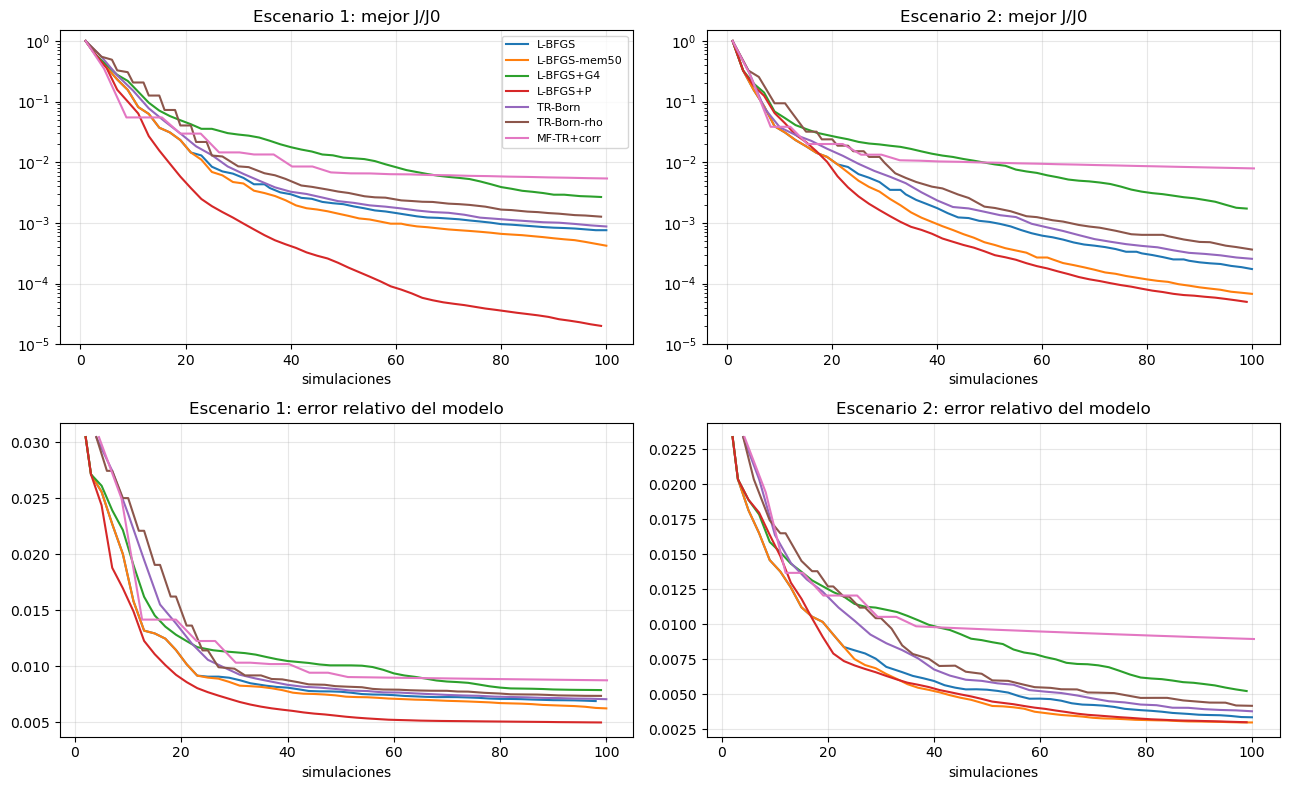

In [3]:
MAIN = ["L-BFGS", "L-BFGS-mem50", "L-BFGS+G4", "L-BFGS+P", "TR-Born", "TR-Born-rho", "MF-TR+corr"]

def best_so_far(d, s):
    """Mejor J aceptado vs simulaciones (traza) y error de modelo vs simulaciones (log)."""
    tr = np.array(d["trace"]); jb = np.minimum.accumulate(tr[:, 1]) / J0[s]
    lg = [(e["sims"], e["err"]) for e in d["log"] if "err" in e]
    return tr[:, 0], jb, np.array(lg)

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for j, s in enumerate(SCEN):
    for n in MAIN:
        if n not in R[s]:
            continue
        x, jb, lg = best_so_far(R[s][n], s)
        ax[0, j].semilogy(x, jb, label=n)
        ax[1, j].plot(lg[:, 0], lg[:, 1], label=n)
    ax[0, j].set(title=f"Escenario {s}: mejor J/J0", xlabel="simulaciones", ylim=(1e-5, 1.5))
    ax[1, j].set(title=f"Escenario {s}: error relativo del modelo", xlabel="simulaciones")
    ax[0, j].grid(alpha=.3); ax[1, j].grid(alpha=.3)
ax[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Modelos finales

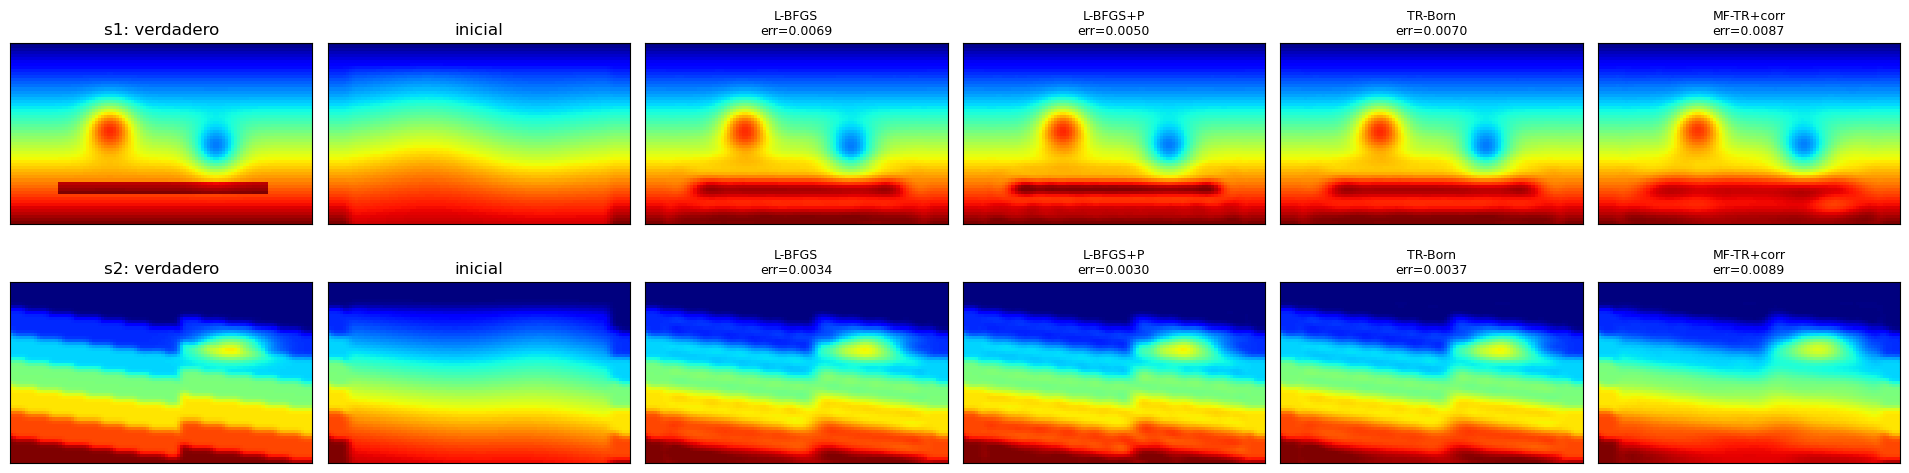

In [4]:
SHOW = ["L-BFGS", "L-BFGS+P", "TR-Born", "MF-TR+corr"]
fig, ax = plt.subplots(2, 2 + len(SHOW), figsize=(3.2 * (2 + len(SHOW)), 5.2))
for i, s in enumerate(SCEN):
    vt, vi = MOD[s]["v_true"], MOD[s]["v_init"]
    kw = dict(vmin=vt.min(), vmax=vt.max(), cmap="jet")
    ax[i, 0].imshow(vt, **kw); ax[i, 0].set_title(f"s{s}: verdadero")
    ax[i, 1].imshow(vi, **kw); ax[i, 1].set_title("inicial")
    for k, n in enumerate(SHOW):
        m = R[s][n]["m"].numpy()
        v = m if m.shape == vt.shape else None
        if v is None:
            ax[i, 2 + k].set_title(f"{n}: forma {m.shape}"); continue
        ax[i, 2 + k].imshow(v, **kw); ax[i, 2 + k].set_title(f"{n}\nerr={R[s][n]['err']:.4f}", fontsize=9)
for a in ax.flat:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Idea 1: precondicionador aprendido. Ablaciones y controles

P q = A Aᵀ q + εγ q, con A v = a ⊙ (K ⋆ v). Aquí a(x,z) es una iluminación suave (malla 6×10) y K un kernel 9×9.
Se ajusta con Adam a la ecuación secante inversa P yᵢ ≈ sᵢ usando **todos** los pares del historial, y sustituye a
H0 = γI en el two-loop de L-BFGS.

**Controles**, necesarios para saber si la ganancia viene de *aprender*:
- `L-BFGS-mem50`: usar más memoria también aprovecha todo el historial.
- `L-BFGS+G2`, `L-BFGS+G4`: H0 = γ[(1−ε)G_σ∗G_σ + ε], un filtro gaussiano fijo **sin aprendizaje** con la misma
  forma que P.
- `-illum` y `-kernel`: aprenden solo una de las dos partes.
- `eps0.3`, `k5`, `reg0.1`: sensibilidad a hiperparámetros.
- `transfer`: P aprendido en el escenario 1 y aplicado congelado (o con ajuste fino, `-ft`) al escenario 2.

In [5]:
P_ROWS = ["L-BFGS", "L-BFGS-mem50", "L-BFGS+G2", "L-BFGS+G4", "L-BFGS+P", "L-BFGS+P-illum", "L-BFGS+P-kernel",
          "L-BFGS+P-eps0.3", "L-BFGS+P-k5", "L-BFGS+P-reg0.1", "L-BFGS+P-transfer", "L-BFGS+P-transfer-ft"]
rows = {}
for n in P_ROWS:
    rows[n] = {f"s{s} J/J0": R[s][n]["J"] / J0[s] if n in R[s] else np.nan for s in SCEN}
    rows[n].update({f"s{s} err": R[s][n]["err"] if n in R[s] else np.nan for s in SCEN})
display(pd.DataFrame(rows).T)

,s1 J/J0,s2 J/J0,s1 err,s2 err
L-BFGS,0.000759,0.000174,0.0069,0.00335
L-BFGS-mem50,0.000421,6.77e-05,0.00625,0.00298
L-BFGS+G2,0.00176,0.00107,0.00764,0.0051
L-BFGS+G4,0.00268,0.00173,0.00788,0.00523
L-BFGS+P,2.01e-05,4.99e-05,0.00499,0.003
L-BFGS+P-illum,0.000252,0.000228,0.0059,0.00328
L-BFGS+P-kernel,8.31e-05,4.83e-05,0.00536,0.00336
L-BFGS+P-eps0.3,2.16e-05,NaN,0.00497,NaN
L-BFGS+P-k5,3.03e-05,NaN,0.00506,NaN
L-BFGS+P-reg0.1,2.28e-05,NaN,0.00502,NaN


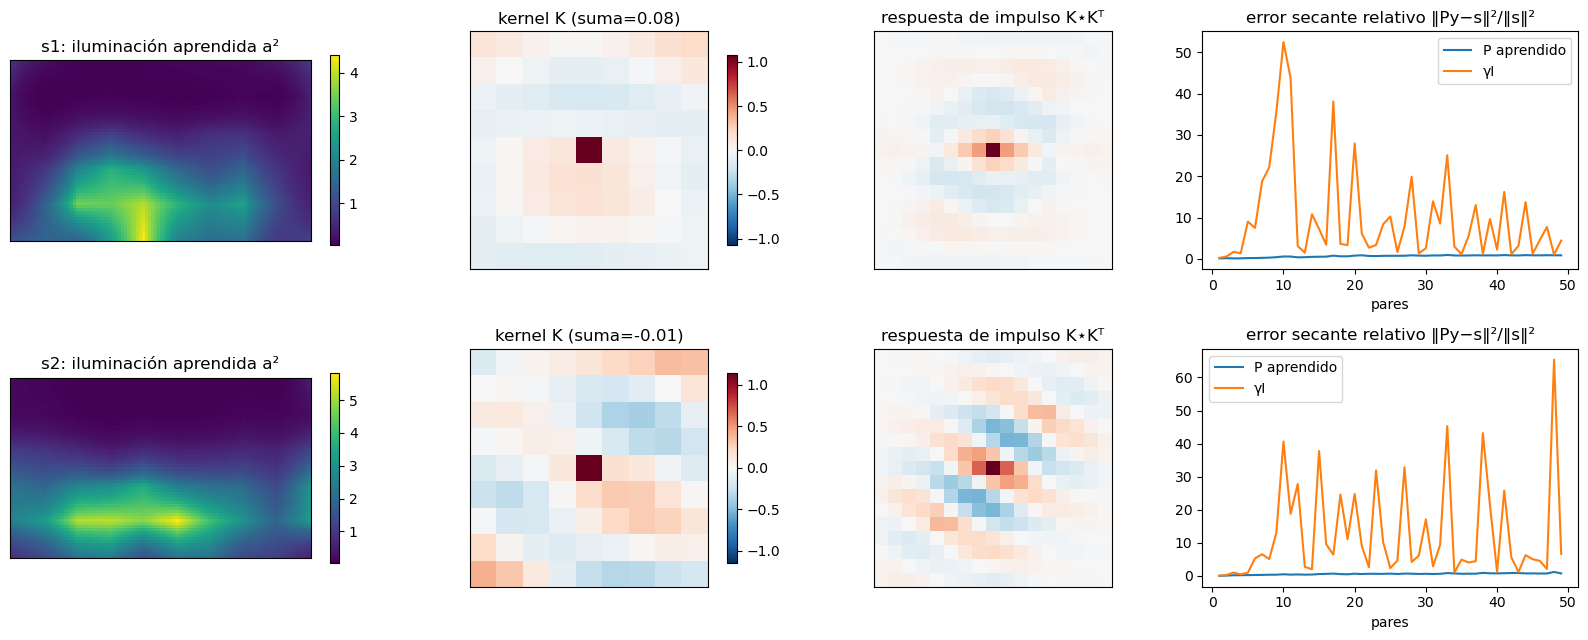

In [6]:
fig, ax = plt.subplots(2, 4, figsize=(16, 6.5))
for i, s in enumerate(SCEN):
    pc = R[s]["L-BFGS+P"]["precond"]
    im = ax[i, 0].imshow(pc["illum"], cmap="viridis"); plt.colorbar(im, ax=ax[i, 0], shrink=.8)
    ax[i, 0].set_title(f"s{s}: iluminación aprendida a²")
    K = pc["K"][0, 0].numpy(); km = np.abs(K).max()
    im = ax[i, 1].imshow(K, cmap="RdBu_r", vmin=-km, vmax=km); plt.colorbar(im, ax=ax[i, 1], shrink=.8)
    ax[i, 1].set_title(f"kernel K (suma={K.sum():.2f})")
    from scipy.signal import correlate2d
    KK = correlate2d(K, K); kk = np.abs(KK).max()
    ax[i, 2].imshow(KK, cmap="RdBu_r", vmin=-kk, vmax=kk); ax[i, 2].set_title("respuesta de impulso K⋆Kᵀ")
    h = pc["history"]
    ax[i, 3].plot([e["n_pairs"] for e in h], [e["loss"] for e in h], label="P aprendido")
    ax[i, 3].plot([e["n_pairs"] for e in h], [e["loss_gammaI"] for e in h], label="γI")
    ax[i, 3].set(title="error secante relativo ‖Py−s‖²/‖s‖²", xlabel="pares"); ax[i, 3].legend()
for a in ax[:, :3].flat:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Idea 2: surrogate multifidelidad con región de confianza

J̃(s) = ½‖r + C(F_c(m+s) − F_c(m))‖² + (g − ∇)ᵀs. F_c es la malla gruesa (fac=2, 1/8 del costo) y C son filtros
temporales por rango de offset, ajustados online a los pares (δd_grueso, δd_fino). Cada evaluación gruesa
forward cuenta como 0.125 simulaciones y una forward+adjunta como 0.25.

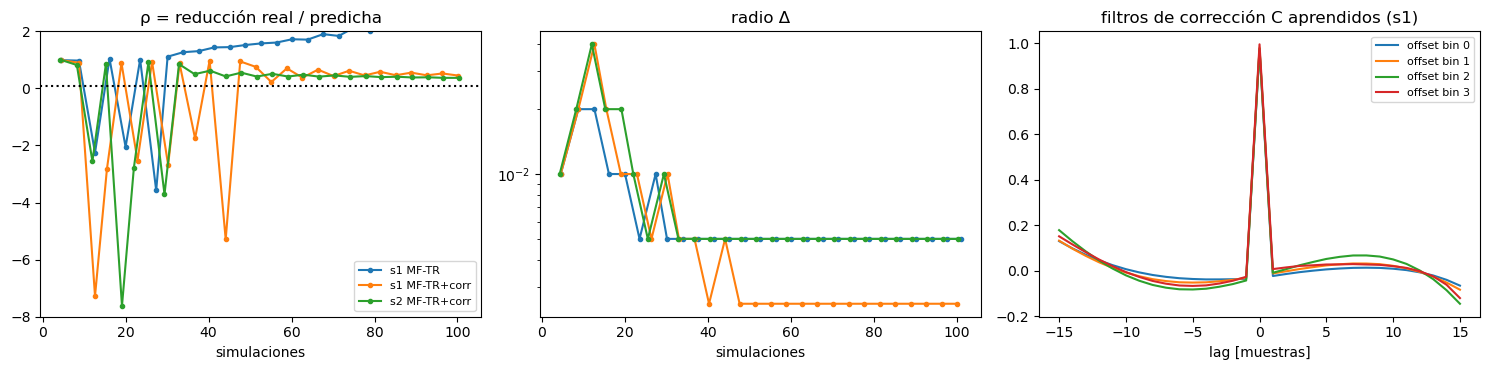

s1 MF-TR      : iteraciones=27, aceptadas=24, ρ mediana últimas 10 = 2.34
s1 MF-TR+corr : iteraciones=27, aceptadas=21, ρ mediana últimas 10 = 0.49
s2 MF-TR+corr : iteraciones=27, aceptadas=23, ρ mediana últimas 10 = 0.40


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for s in SCEN:
    for n in ["MF-TR", "MF-TR+corr"]:
        if n not in R[s]:
            continue
        lg = R[s][n]["log"]
        x = [e["sims"] for e in lg]
        ax[0].plot(x, [e["rho"] for e in lg], ".-", label=f"s{s} {n}")
        ax[1].semilogy(x, [e["Delta"] for e in lg], ".-", label=f"s{s} {n}")
ax[0].set(title="ρ = reducción real / predicha", xlabel="simulaciones", ylim=(-8, 2)); ax[0].axhline(0.1, c="k", ls=":")
ax[1].set(title="radio Δ", xlabel="simulaciones"); ax[0].legend(fontsize=8)
h = R[1]["MF-TR+corr"].get("corr_h")
if h is not None:
    for b in range(h.shape[0]):
        ax[2].plot(np.arange(h.shape[-1]) - h.shape[-1] // 2, h[b].numpy(), label=f"offset bin {b}")
    ax[2].set(title="filtros de corrección C aprendidos (s1)", xlabel="lag [muestras]"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
for s in SCEN:
    for n in ["MF-TR", "MF-TR+corr"]:
        if n in R[s]:
            lg = R[s][n]["log"]
            print(f"s{s} {n:11s}: iteraciones={len(lg)}, aceptadas={sum(e['accepted'] for e in lg)}, "
                  f"ρ mediana últimas 10 = {np.median([e['rho'] for e in lg[-10:]]):.2f}")

## Idea 3: ¿cuándo pedir la simulación Born?

- `never`: ajuste multisecante puro.
- `always`: un Born en g_k tras cada paso aceptado.
- `adaptive`: Born en el paso propuesto si la incertidumbre bayesiana de U supera un umbral.
- `rho`: Born solo si el paso aceptado tuvo |ρ−1| > 0.25.

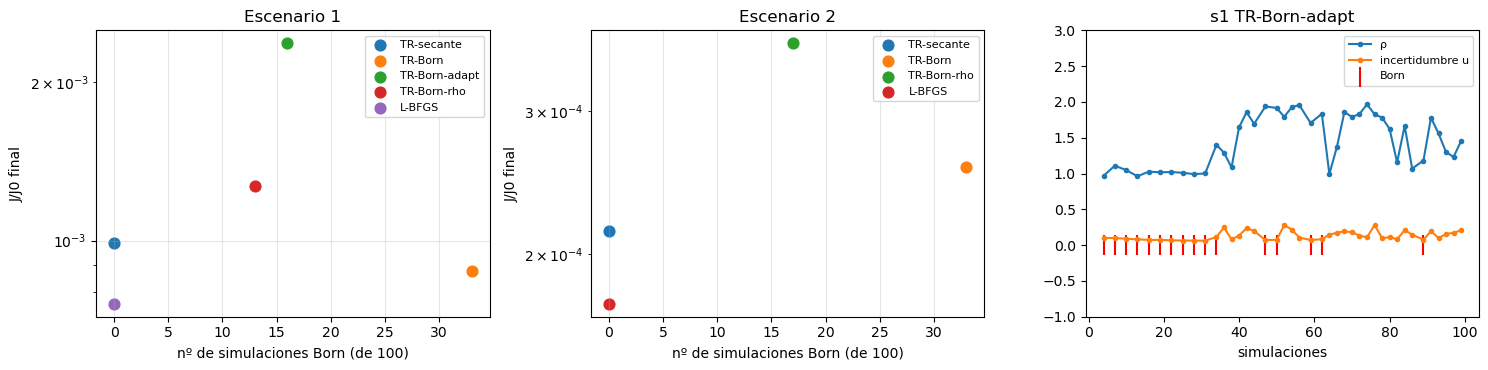

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for k, s in enumerate(SCEN):
    for n in ["TR-secante", "TR-Born", "TR-Born-adapt", "TR-Born-rho", "L-BFGS"]:
        if n in R[s]:
            ax[k].scatter(R[s][n]["n_born"], R[s][n]["J"] / J0[s], s=60, label=n)
    ax[k].set(yscale="log", xlabel="nº de simulaciones Born (de 100)", ylabel="J/J0 final", title=f"Escenario {s}")
    ax[k].legend(fontsize=8); ax[k].grid(alpha=.3)
lg = R[1]["TR-Born-adapt"]["log"]
ax[2].plot([e["sims"] for e in lg], [e["rho"] for e in lg], ".-", label="ρ")
ax[2].plot([e["sims"] for e in lg], [e["unc"] for e in lg], ".-", label="incertidumbre u")
ax[2].scatter([e["sims"] for e in lg if e["born"]], [0] * sum(e["born"] for e in lg), c="r", marker="|", s=200, label="Born")
ax[2].set(title="s1 TR-Born-adapt", xlabel="simulaciones", ylim=(-1, 3)); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Conclusiones

Todas las comparaciones usan el mismo presupuesto (100 simulaciones caras).

**1. Precondicionador aprendido: es la idea ganadora, y su ganancia sobrevive a los controles.**

- **Escenario 1:**
  - J/J0 ≈ 2e-5, frente a 7.6e-4 con L-BFGS (≈36× menos) y 4.2e-4 con L-BFGS-mem50 (≈20× menos).
  - Error de modelo 0.0050, frente a 0.0069 y 0.0063.
- **Control decisivo:** un H0 gaussiano fijo con la misma forma pero sin aprender (G2, G4) queda *peor* que
  L-BFGS en ambos escenarios. La ganancia no viene de "suavizar más", sino de lo que se aprende.
- **Robustez:** el resultado es insensible a ε (0.1 → 0.3), al tamaño del kernel (9 → 5) y a la regularización
  (×10). Al repetir la corrida en GPU sale J = 6.7e-5 frente a 7.1e-5 (absoluto).
- **Qué parte importa:** casi todo el efecto viene del kernel (acoplamiento espacial). Aprender solo la iluminación
  ayuda poco.
- **Escenario 2 (capas y falla), la ganancia es mucho menor:**
  - J/J0 = 5.0e-5, frente a 1.7e-4 con L-BFGS (3.5×) y 6.8e-5 con mem50 (1.4×).
  - El error de modelo es igual al de mem50 (0.0030).
  - Parte del beneficio equivale simplemente a "usar todo el historial".
- **Transferencia:** un P aprendido en s1 y aplicado congelado a s2 empeora el modelo (err 0.0044). Con ajuste fino
  recupera (0.0031). El precondicionador hay que aprenderlo online para cada caso; no es reutilizable tal cual.
- **Advertencia:** P ajusta los pares históricos mucho mejor que γI (el escalado γ del último par es inestable).
  Aun así, su error secante relativo sigue siendo ≈0.5–1, así que no aproxima bien el Hessiano inverso. Funciona
  como un H0 con escala y acoplamiento espacial coherentes con todo el historial, y L-BFGS lo corrige.

**2. Surrogate multifidelidad: falla en esta configuración.**

- La malla gruesa (≈2.4 puntos por longitud de onda) tiene una dispersión numérica que deja un error relativo
  de ≈0.36 en δd (correlación 0.93). La corrección aprendida solo lo baja a ≈0.30.
- En cuanto el residuo se reduce, ese error domina. Aparecen ρ muy negativos (−2 a −7), los pasos se rechazan y
  Δ cae al mínimo, donde ya solo se dan pasos diminutos.
- Resultado final: J/J0 ≈ 5e-3–1e-2, de 7 a 45 veces peor que L-BFGS.
- Es esencialmente MG/OPT (Nash 2000) o RMTR (Gratton, Sartenaer y Toint 2008). Solo sería viable con un modelo
  grueso con error menor que el residuo objetivo, por ejemplo un orden espectral más alto o un surrogate neuronal
  entrenado offline.

**3. Born adaptativo: no compensa.**

- Disparar Born por incertidumbre bayesiana (`adaptive`) ahorra la mitad de los Born, pero estanca la inversión.
  La incertidumbre mide falta de datos, no el sesgo de los pares viejos (no estacionariedad).
- El disparo por ρ (`rho`) usa 13–17 Born y tampoco mejora a `never` ni a `always`.
- Con presupuesto fijo, el Born extra rara vez paga su costo. Ninguna variante TR supera a L-BFGS simple.

**Recomendación para SPECFEM3D:**

- Priorizar el precondicionador aprendido online como H0 de L-BFGS. Su costo es nulo en simulaciones (~1 s de
  ajuste por iteración), es SPD por construcción y no requiere cambiar el flujo forward/adjunto.
- Validarlo siempre contra L-BFGS con memoria grande y contra un precondicionador clásico (pseudo-Hessiano,
  PSF / iluminación), porque en el escenario 2 la ventaja fue pequeña.